LAB 4

Conor Murray

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from linearmodels.panel import PooledOLS, PanelOLS, RandomEffects
from linearmodels.panel import compare

In [4]:
df = pd.read_csv("Brazilian Fuel Demand.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   i              432 non-null    int64  
 1   t              432 non-null    int64  
 2   ln_Sg_pc       432 non-null    float64
 3   ln_Pg          432 non-null    float64
 4   ln_l1_Pg       432 non-null    float64
 5   ln_l2_Pg       432 non-null    float64
 6   ln_Pe          432 non-null    float64
 7   ln_l1_Pe       432 non-null    float64
 8   ln_l2_Pe       432 non-null    float64
 9   ln_Mi_e        432 non-null    float64
 10  ln_W_adj_Mi_e  432 non-null    float64
 11  ln_Mi_c        432 non-null    float64
 12  ln_gdp_pc      432 non-null    float64
dtypes: float64(11), int64(2)
memory usage: 44.0 KB


In [5]:
df.describe()

,i,t,ln_Sg_pc,ln_Pg,ln_l1_Pg,ln_l2_Pg,ln_Pe,ln_l1_Pe,ln_l2_Pe,ln_Mi_e,ln_W_adj_Mi_e,ln_Mi_c,ln_gdp_pc
count,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000
mean,29.111111,2013.500000,-1.809428,0.779752,0.780370,0.790390,0.512349,0.501660,0.500296,-4.988134,0.159893,-1.446987,2.528276
std,12.795978,4.615117,0.414799,0.101338,0.102282,0.101997,0.128528,0.119118,0.122093,2.830977,0.626063,0.502187,0.471329
min,11.000000,2006.000000,-3.005074,0.506757,0.506757,0.600429,0.138021,0.138021,0.066069,-10.622686,-0.993426,-2.988360,1.453385
25%,17.000000,2009.750000,-2.014121,0.698396,0.698396,0.707013,0.437206,0.435218,0.430467,-7.510011,-0.316652,-1.774392,2.198080
50%,27.000000,2013.500000,-1.829438,0.760806,0.760806,0.780700,0.506034,0.503620,0.501775,-4.916052,0.004776,-1.394293,2.460892
75%,41.000000,2017.250000,-1.499243,0.848793,0.848354,0.860218,0.593078,0.578788,0.579152,-2.723529,0.778176,-1.055215,2.904192
max,53.000000,2021.000000,-0.875714,1.081805,1.081805,1.081805,0.895312,0.841567,0.841567,1.199500,1.545784,-0.565304,3.817740


In [6]:
df = df.rename(columns={'i': 'state', 't': 'year'})
df = df.set_index(['state', 'year'])
df = df.sort_index()
print(df.head())
print()
print('Index levels:', df.index.names)

            ln_Sg_pc     ln_Pg  ln_l1_Pg  ln_l2_Pg     ln_Pe  ln_l1_Pe  \
state year                                                               
11    2006 -2.156699  1.004302  0.974824  0.961723  0.760806  0.624226   
      2007 -2.073636  0.942192  1.004302  0.974824  0.598232  0.760806   
      2008 -1.956062  0.896006  0.942192  1.004302  0.519627  0.598232   
      2009 -1.862154  0.842644  0.896006  0.942192  0.477414  0.519627   
      2010 -1.683161  0.818281  0.842644  0.896006  0.522122  0.477414   

            ln_l2_Pe   ln_Mi_e  ln_W_adj_Mi_e   ln_Mi_c  ln_gdp_pc  
state year                                                          
11    2006  0.562469 -7.353989       1.044721 -1.951172   2.122915  
      2007  0.624226 -7.331709       1.044721 -1.799154   2.202302  
      2008  0.760806 -7.308921       1.044721 -1.620767   2.347745  
      2009  0.598232 -7.315836       1.044721 -1.477053   2.430651  
      2010  0.519627 -7.339662       1.044721 -1.362601   2.541726 

The dataset is balenced

In [7]:
df['post'] = 0
years = df.index.get_level_values('year')
mask = (years == 2020) | (years == 2021)
df.loc[mask, 'post'] = 1
print(df['post'].value_counts())
print()
print(df.groupby(level='year')['post'].mean())

post
0    378
1     54
Name: count, dtype: int64

year
2006    0.0
2007    0.0
2008    0.0
2009    0.0
2010    0.0
2011    0.0
2012    0.0
2013    0.0
2014    0.0
2015    0.0
2016    0.0
2017    0.0
2018    0.0
2019    0.0
2020    1.0
2021    1.0
Name: post, dtype: float64


C:\Users\conor\AppData\Local\Temp\ipykernel_27488\1945444128.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


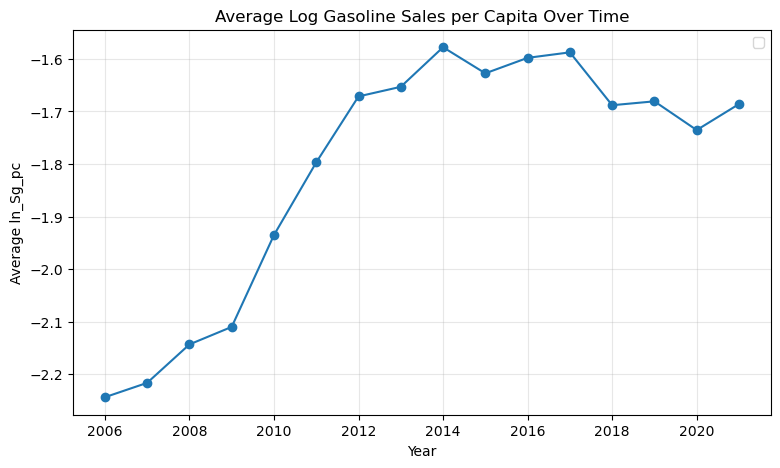

year
2006   -2.243
2007   -2.216
2008   -2.143
2009   -2.110
2010   -1.935
2011   -1.797
2012   -1.671
2013   -1.653
2014   -1.578
2015   -1.628
2016   -1.598
2017   -1.588
2018   -1.688
2019   -1.681
2020   -1.735
2021   -1.686
Name: ln_Sg_pc, dtype: float64


In [8]:
avg_by_year = df.groupby(level='year')['ln_Sg_pc'].mean()
plt.figure(figsize=(9, 5))
plt.plot(avg_by_year.index, avg_by_year.values, marker='o')
plt.title('Average Log Gasoline Sales per Capita Over Time')
plt.xlabel('Year')
plt.ylabel('Average ln_Sg_pc')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(avg_by_year.round(3))

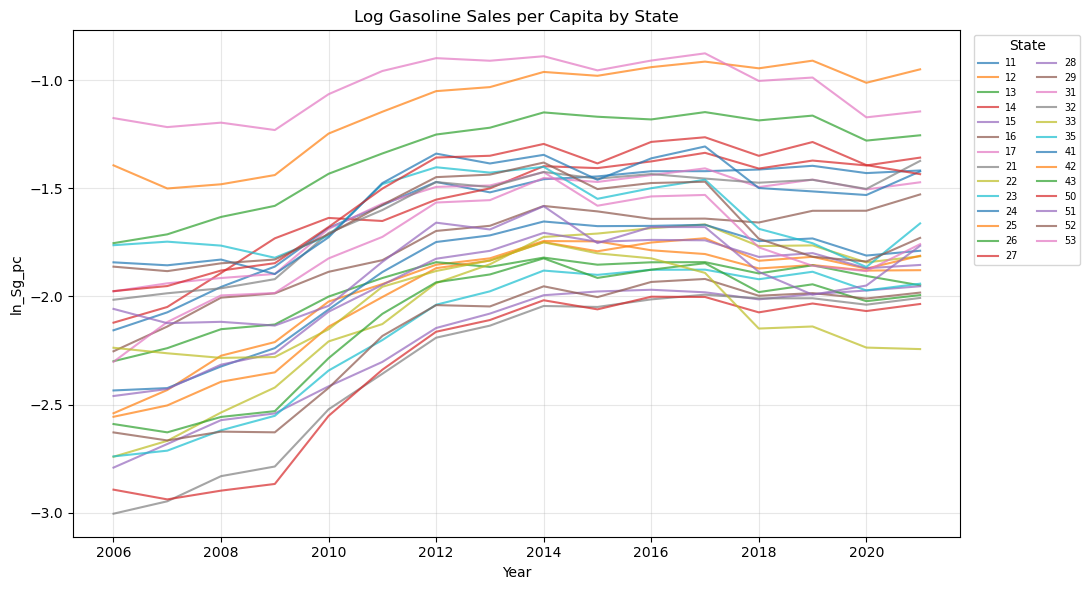

Lowest average state: 27 -2.316
Highest average state: 53 -1.036


In [9]:
plt.figure(figsize=(11, 6))
state_list = df.index.get_level_values('state').unique()
for s in state_list:
    sub = df.loc[s]
    plt.plot(sub.index, sub['ln_Sg_pc'], alpha=0.7, label=str(s))
plt.title('Log Gasoline Sales per Capita by State')
plt.xlabel('Year')
plt.ylabel('ln_Sg_pc')
plt.legend(title='State', ncol=2, fontsize=7, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
state_means = df.groupby(level='state')['ln_Sg_pc'].mean()
state_means = state_means.sort_values()
print('Lowest average state:', state_means.index[0], round(state_means.iloc[0], 3))
print('Highest average state:', state_means.index[-1], round(state_means.iloc[-1], 3))

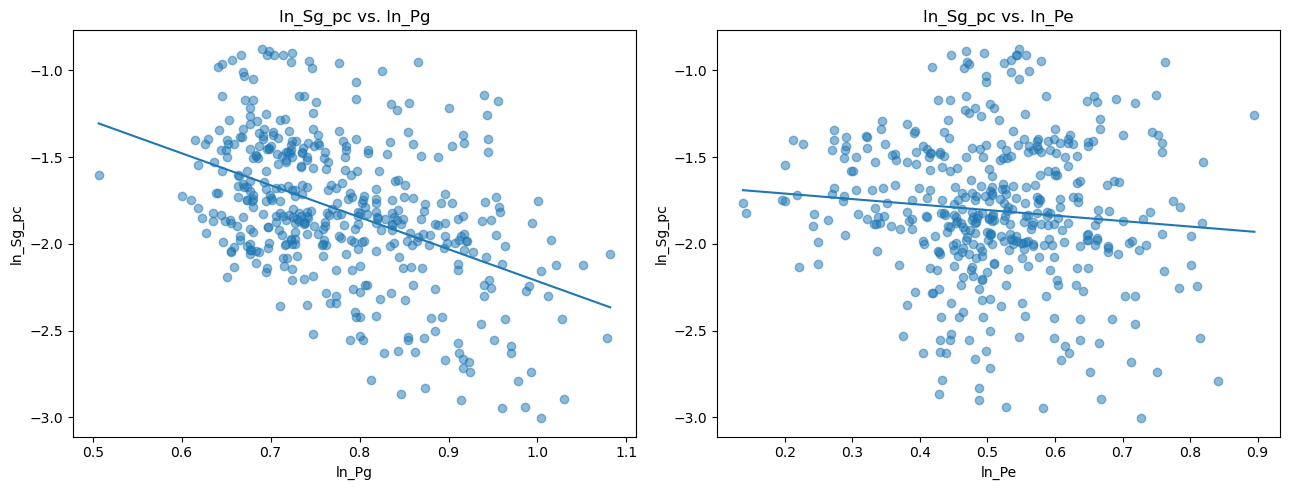

Slope ln_Sg_pc on ln_Pg: -1.844  Correlation: -0.45
Slope ln_Sg_pc on ln_Pe: -0.317  Correlation: -0.098


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(df['ln_Pg'], df['ln_Sg_pc'], alpha=0.5)
slope_g, intercept_g = np.polyfit(df['ln_Pg'], df['ln_Sg_pc'], 1)
x_g = np.linspace(df['ln_Pg'].min(), df['ln_Pg'].max(), 100)
axes[0].plot(x_g, intercept_g + slope_g * x_g)
axes[0].set_title('ln_Sg_pc vs. ln_Pg')
axes[0].set_xlabel('ln_Pg')
axes[0].set_ylabel('ln_Sg_pc')
axes[1].scatter(df['ln_Pe'], df['ln_Sg_pc'], alpha=0.5)
slope_e, intercept_e = np.polyfit(df['ln_Pe'], df['ln_Sg_pc'], 1)
x_e = np.linspace(df['ln_Pe'].min(), df['ln_Pe'].max(), 100)
axes[1].plot(x_e, intercept_e + slope_e * x_e)
axes[1].set_title('ln_Sg_pc vs. ln_Pe')
axes[1].set_xlabel('ln_Pe')
axes[1].set_ylabel('ln_Sg_pc')
plt.tight_layout()
plt.show()
print('Slope ln_Sg_pc on ln_Pg:', round(slope_g, 3), ' Correlation:', round(df['ln_Sg_pc'].corr(df['ln_Pg']), 3))
print('Slope ln_Sg_pc on ln_Pe:', round(slope_e, 3), ' Correlation:', round(df['ln_Sg_pc'].corr(df['ln_Pe']), 3))

Question 2: Dependent variable would be ln_Sg_pc since it is the variable we want to predict
Independent variable would be post since we are using this variable to track the negative effect covid had on gas sales
Control variable would be ln_gdp_pc since higher income means more cars per family and more expensive cars that often use more fuel

In [11]:
controls = ['ln_Pg', 'ln_l1_Pg', 'ln_l2_Pg', 'ln_Pe', 'ln_l1_Pe', 'ln_l2_Pe', 'ln_Mi_c', 'ln_gdp_pc']
y = df['ln_Sg_pc']
X = df[controls]
X = X.copy()
X['const'] = 1
pooled = PooledOLS(y, X).fit()
print(pooled)

                          PooledOLS Estimation Summary                          
Dep. Variable:               ln_Sg_pc   R-squared:                        0.8533
Estimator:                  PooledOLS   R-squared (Between):              0.8440
No. Observations:                 432   R-squared (Within):               0.8694
Date:                Thu, Oct 29 2026   R-squared (Overall):              0.8533
Time:                        14:12:15   Log-likelihood                    182.30
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      307.65
Entities:                          27   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                   F(8,423)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             307.65
                            

In [12]:
fe = PanelOLS(y, X, entity_effects=True).fit()
print(fe)

                          PanelOLS Estimation Summary                           
Dep. Variable:               ln_Sg_pc   R-squared:                        0.9070
Estimator:                   PanelOLS   R-squared (Between):              0.7510
No. Observations:                 432   R-squared (Within):               0.9070
Date:                Thu, Oct 29 2026   R-squared (Overall):              0.8082
Time:                        14:12:15   Log-likelihood                    497.15
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      483.72
Entities:                          27   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                   F(8,397)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             483.72
                            

In [14]:
re = RandomEffects(y, X).fit()
print(re)

                        RandomEffects Estimation Summary                        
Dep. Variable:               ln_Sg_pc   R-squared:                        0.8993
Estimator:              RandomEffects   R-squared (Between):              0.7682
No. Observations:                 432   R-squared (Within):               0.9065
Date:                Thu, Oct 29 2026   R-squared (Overall):              0.8189
Time:                        14:14:42   Log-likelihood                    468.54
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      472.30
Entities:                          27   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                   F(8,423)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             472.30
                            

In [15]:
print(compare({'Pooled OLS': pooled, 'Fixed Effects': fe, 'Random Effects': re}, stars=True))

                            Model Comparison                           
                            Pooled OLS  Fixed Effects    Random Effects
-----------------------------------------------------------------------
Dep. Variable                 ln_Sg_pc       ln_Sg_pc          ln_Sg_pc
Estimator                    PooledOLS       PanelOLS     RandomEffects
No. Observations                   432            432               432
Cov. Est.                   Unadjusted     Unadjusted        Unadjusted
R-squared                       0.8533         0.9070            0.8993
R-Squared (Within)              0.8694         0.9070            0.9065
R-Squared (Between)             0.8440         0.7510            0.7682
R-Squared (Overall)             0.8533         0.8082            0.8189
F-statistic                     307.65         483.72            472.30
P-value (F-stat)                0.0000         0.0000            0.0000
=====================     ============   ============   ========

Question 3: Fixed effects is the best model to use on the given data

In [20]:
final_vars = controls + ['ln_Mi_e', 'post']
X_final = df[final_vars]
X_final = X_final.copy()
X_final['const'] = 1
final_model = PanelOLS(y, X_final, entity_effects=True).fit()
print(final_model)
print(compare({'Baseline FE': fe, 'With EV and COVID': final_model}, stars=True))

                          PanelOLS Estimation Summary                           
Dep. Variable:               ln_Sg_pc   R-squared:                        0.9406
Estimator:                   PanelOLS   R-squared (Between):              0.6996
No. Observations:                 432   R-squared (Within):               0.9406
Date:                Thu, Oct 29 2026   R-squared (Overall):              0.7881
Time:                        14:22:27   Log-likelihood                    594.26
Cov. Estimator:            Unadjusted                                           
                                        F-statistic:                      626.03
Entities:                          27   P-value                           0.0000
Avg Obs:                       16.000   Distribution:                  F(10,395)
Min Obs:                       16.000                                           
Max Obs:                       16.000   F-statistic (robust):             626.03
                            

Question 4


The best fitting model is the fixed effects model. The within R squared is 0.907 which is the highest of the three models I tested. this means the model explains over 90% of variations in gas sales after running the final model this nubmer jumped up to 94%. 
Change in income does not have an effect on how much fuel is bought since the main reason to buy fuel is neccessity of getting to a place. 
Since ethenol is used to make gasoline anytime ethonal prices incease so do gasoline prices. This makes sense since manufacters must increase fuel cost to break even since matierals are costing more.


Covid had a negative effect on fuel demand as people started driving less they need to buy less gas, This is a simualar case to EVs which dont need gasoline either and take a potential fuel buying custoemr off the market completely.
These both have a negative effect on fuel sales by lowering the demand and potential clients of what is usually considered a necessity. 

The results show that although EV adaptation is slow it does have a small effect on fuel sales that will slowly increase over time. As more charging stations open up so will more EVs be driving , but at the current state gasoline still has the monopoly.
Energy policy is going to be a driving factor to push up EV sales and slowly decrease fuel sales, oil companies can look for tax breaks or other incetives to help continue turning a profit as energy policy helps put more EVs on the road which in turn leads to more EV charging stations and less gas fuel stations

The model is not a Did analysis, since there is no untested control group to compare the "post" group too. Since all the states are all being recorded before and after covid they are all aprt of the same group making it impossible to call this a difference in differnce analysis